In [1]:
# Cell 1 - imports and basic config
import os
import random
import math
import glob
from collections import Counter, defaultdict
from datetime import datetime
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms, models
from torchvision.transforms import InterpolationMode
from torch.cuda.amp import autocast, GradScaler

from sklearn.model_selection import GroupShuffleSplit, StratifiedKFold
from sklearn.metrics import (confusion_matrix, classification_report,
                             roc_auc_score, roc_curve, auc, accuracy_score, f1_score)

import timm   # for flexible pretrained models
from torchsummary import summary

# reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# GPU check
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


C:\Users\sanja\anaconda3\envs\gpu_env\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda


In [2]:
# Cell 2 - user dataset path and class mapping
# Use raw string for Windows path
datasetPath = r"C:\Users\sanja\Desktop\MRI_Project\AD_DATASET\Data"

# Provided folder names (user-specified)
class_folders = {
    "Non Demented": "non_demented",
    "Very mild Dementia": "very_mild_demented",
    "Mild Dementia": "mild_demented",
    "Moderate Dementia": "moderate_demented"
}

# We'll map folder display names to indices
label_map = {
    "Non Demented": 0,
    "Very mild Dementia": 1,
    "Mild Dementia": 2,
    "Moderate Dementia": 3
}

# inverse map
inv_label_map = {v:k for k,v in label_map.items()}

# Verify folders
found = {}
for name in label_map.keys():
    folder = os.path.join(datasetPath, name)
    found[name] = os.path.isdir(folder)
found


{'Non Demented': True,
 'Very mild Dementia': True,
 'Mild Dementia': True,
 'Moderate Dementia': True}

In [3]:
# Cell 3 - build dataframe of filepaths and labels
# This reads images recursively from the 4 folders, gets filename and subject id by prefix (before first underscore).
rows = []
for label_name, label_idx in label_map.items():
    folder = os.path.join(datasetPath, label_name)
    if not os.path.isdir(folder):
        continue
    # gather jpg/png files
    patterns = [os.path.join(folder, "*.jpg"), os.path.join(folder, "*.png"), os.path.join(folder, "*.jpeg")]
    files = []
    for p in patterns:
        files.extend(glob.glob(p))
    for f in files:
        fname = os.path.basename(f)
        # Extract subject prefix (assumes e.g., OAS1_0028_... )
        subj = fname.split('_')[0] if '_' in fname else fname.split('.')[0]
        rows.append({"filepath": f, "label_idx": label_idx, "label_name": label_name, "filename": fname, "subject": subj})

df = pd.DataFrame(rows)
print("Total images:", len(df))
df.label_name.value_counts()


Total images: 86437


label_name
Non Demented          67222
Very mild Dementia    13725
Mild Dementia          5002
Moderate Dementia       488
Name: count, dtype: int64

                class  counts
0        Non Demented   67222
1  Very mild Dementia   13725
2       Mild Dementia    5002
3   Moderate Dementia     488


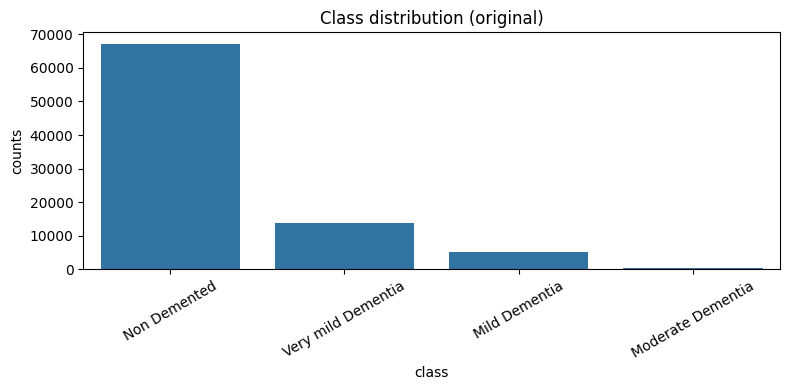

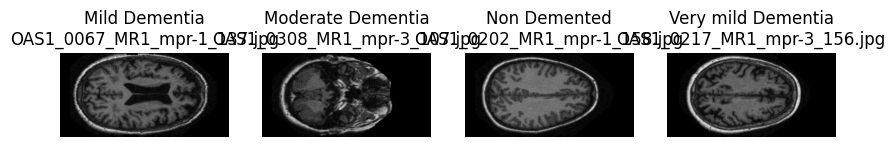

In [4]:
# Cell 4 - Basic EDA: class counts and sample images
counts = df.label_name.value_counts().rename_axis('class').reset_index(name='counts')
print(counts)
plt.figure(figsize=(8,4))
sns.barplot(x='class', y='counts', data=counts)
plt.xticks(rotation=30)
plt.title("Class distribution (original)")
plt.tight_layout()
plt.show()

# Show sample images (up to 4)
sample = df.groupby('label_name').sample(n=1, random_state=SEED).reset_index(drop=True)
plt.figure(figsize=(10,4))
for i, row in sample.iterrows():
    img = Image.open(row.filepath)
    plt.subplot(1,4,i+1)
    plt.imshow(img)
    plt.title(f"{row.label_name}\n{row.filename}")
    plt.axis('off')
plt.show()


In [5]:
# Cell 5 - One-hot encoding of labels (store in dataframe)
df['label_onehot'] = df['label_idx'].apply(lambda x: np.eye(len(label_map),dtype=int)[x].tolist())
df.head()


,filepath,label_idx,label_name,filename,subject,label_onehot
0,C:\Users\sanja\Desktop\MRI_Project\AD_DATASET\...,0,Non Demented,OAS1_0001_MR1_mpr-1_100.jpg,OAS1,"[1, 0, 0, 0]"
1,C:\Users\sanja\Desktop\MRI_Project\AD_DATASET\...,0,Non Demented,OAS1_0001_MR1_mpr-1_101.jpg,OAS1,"[1, 0, 0, 0]"
2,C:\Users\sanja\Desktop\MRI_Project\AD_DATASET\...,0,Non Demented,OAS1_0001_MR1_mpr-1_102.jpg,OAS1,"[1, 0, 0, 0]"
3,C:\Users\sanja\Desktop\MRI_Project\AD_DATASET\...,0,Non Demented,OAS1_0001_MR1_mpr-1_103.jpg,OAS1,"[1, 0, 0, 0]"
4,C:\Users\sanja\Desktop\MRI_Project\AD_DATASET\...,0,Non Demented,OAS1_0001_MR1_mpr-1_104.jpg,OAS1,"[1, 0, 0, 0]"


In [6]:
from sklearn.model_selection import train_test_split

train_df, rest_df = train_test_split(df, test_size=0.30, stratify=df['label_idx'], random_state=SEED)
val_df, test_df = train_test_split(rest_df, test_size=0.50, stratify=rest_df['label_idx'], random_state=SEED)

df.loc[train_df.index, 'split'] = 'train'
df.loc[val_df.index, 'split'] = 'val'
df.loc[test_df.index, 'split'] = 'test'


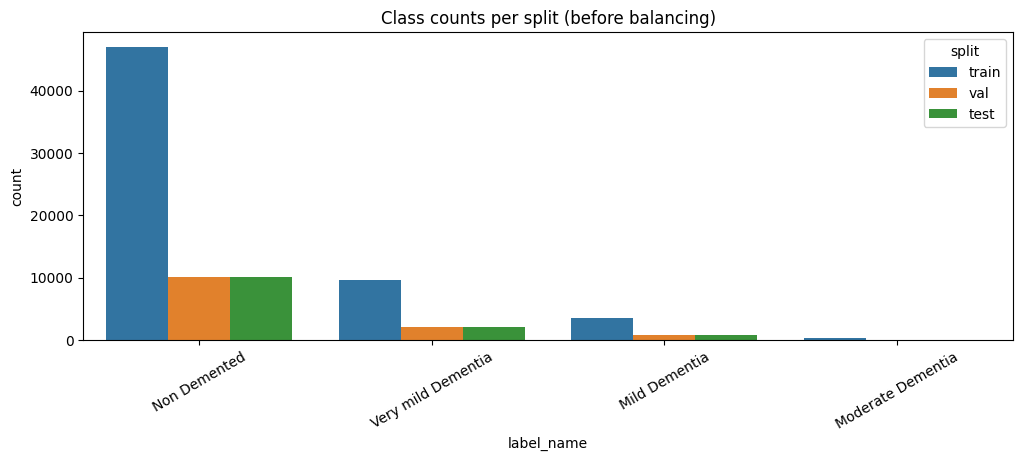

In [7]:
# Cell 7 - Show class distribution before balancing (per split)
plt.figure(figsize=(12,4))
sns.countplot(data=df, x='label_name', hue='split')
plt.xticks(rotation=30)
plt.title("Class counts per split (before balancing)")
plt.show()


In [8]:
# Cell 8 - Transforms and Dataset class
BATCH_SIZE = 32
IMG_SIZE = 96


# ImageNet mean/std for pretrained nets (RGB)
mean = [0.485, 0.456, 0.406]
std  = [0.229, 0.224, 0.225]

train_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])


val_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE), interpolation=InterpolationMode.BILINEAR),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

class MRIDataset(Dataset):
    def __init__(self, df, split, transform=None):
        self.df = df[df['split']==split].reset_index(drop=True)
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = Image.open(row.filepath).convert('RGB')  # force RGB
        if self.transform:
            img = self.transform(img)
        label = int(row.label_idx)
        return img, label, row.filename, row.subject


In [9]:
# Cell 9 - WeightedRandomSampler setup to mitigate class imbalance
# Compute weights based on training set
num_workers = 2        # if Windows; 4–8 if Linux
pin_memory = True
persistent_workers = True   # add this flag


train_df = df[df['split']=='train']
class_counts = train_df['label_idx'].value_counts().sort_index().values
print("Train class counts:", class_counts)
class_weights = 1.0 / (class_counts + 1e-6)
sample_weights = train_df['label_idx'].map(lambda x: class_weights[x]).values
# Map sample weights for entire train indices order in dataset
train_dataset = MRIDataset(df, split='train', transform=train_transforms)

# WeightedRandomSampler requires a weight per sample index in the dataset
sampler = WeightedRandomSampler(weights=sample_weights, num_samples=len(sample_weights), replacement=True)

# DataLoaders
num_workers = min(8, os.cpu_count() or 4)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, sampler=sampler,
                          num_workers=num_workers, pin_memory=True)
val_loader = DataLoader(MRIDataset(df, split='val', transform=val_transforms),
                        batch_size=BATCH_SIZE, shuffle=False, num_workers=num_workers, pin_memory=True)
test_loader = DataLoader(MRIDataset(df, split='test', transform=val_transforms),
                        batch_size=BATCH_SIZE, shuffle=False, num_workers=num_workers, pin_memory=True)

print("Train loader batches:", len(train_loader))


Train class counts: [47055  9607  3501   342]
Train loader batches: 1891


In [10]:
# Cell 11 - Mixup utility (GPU friendly)
def mixup_data(x, y, alpha=0.2):
    '''Returns mixed inputs, pairs of targets, and lambda'''
    if alpha <= 0:
        return x, y, None
    lam = np.random.beta(alpha, alpha)
    batch_size = x.size()[0]
    index = torch.randperm(batch_size).to(x.device)
    mixed_x = lam * x + (1 - lam) * x[index, :]
    y_a, y_b = y, y[index]
    return mixed_x, y_a, y_b, lam

def mixup_criterion(criterion, pred, y_a, y_b, lam):
    return lam * criterion(pred, y_a) + (1 - lam) * criterion(pred, y_b)


In [11]:
# Cell 12 - Focal loss implementation (works with class weights)
class FocalLoss(nn.Module):
    def __init__(self, gamma=2.0, weight=None, reduction='mean'):
        super().__init__()
        self.gamma = gamma
        self.weight = weight
        self.reduction = reduction
        self.ce = nn.CrossEntropyLoss(weight=weight, reduction='none')
    def forward(self, input, target):
        logpt = -self.ce(input, target)  # negative CE per sample
        pt = torch.exp(logpt)
        loss = ((1 - pt) ** self.gamma) * (-logpt)
        if self.reduction == 'mean':
            return loss.mean()
        elif self.reduction == 'sum':
            return loss.sum()
        else:
            return loss


In [12]:
# Cell 13 - Model definitions
# (A) Adapted BrainNet-style CNN (small)
class BrainNetLike(nn.Module):
    def __init__(self, num_classes=4, input_channels=3):
        super().__init__()
        # small custom CNN with bottleneck and global pooling
        self.features = nn.Sequential(
            nn.Conv2d(input_channels, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((1,1))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128, 64),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),
            nn.Linear(64, num_classes)
        )
    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

# (B) Pretrained ResNet50 Head (BrainNet_ResNet)
def get_resnet50(num_classes=4, pretrained=True):
    model = models.resnet50(pretrained=pretrained)
    # adapt first conv to accept 3 channels (already is) and final fc
    in_features = model.fc.in_features
    model.fc = nn.Sequential(
        nn.Dropout(0.4),
        nn.Linear(in_features, num_classes)
    )
    return model


In [13]:
# Cell 14 - Model table explanation (simple)
from IPython.display import Markdown, display
md = """
| Model name | Type | Pretrained | Notes |
|---|---:|:---:|---|
| BrainNetLike | Custom CNN | No | Small CNN inspired by BrainNet blocks. Trained from scratch. |
| BrainNet_ResNet | ResNet50 | Yes | Pretrained ImageNet backbone, fine-tuned final layers. Recommended. |
"""
display(Markdown(md))



| Model name | Type | Pretrained | Notes |
|---|---:|:---:|---|
| BrainNetLike | Custom CNN | No | Small CNN inspired by BrainNet blocks. Trained from scratch. |
| BrainNet_ResNet | ResNet50 | Yes | Pretrained ImageNet backbone, fine-tuned final layers. Recommended. |


In [14]:
# Cell 15 - Instantiate model, move to GPU, and show summary
num_classes = len(label_map)
model_choice = "resnet50"  # options: "brainnetlike" or "resnet50"
if model_choice == "brainnetlike":
    model = BrainNetLike(num_classes=num_classes).to(device)
else:
    model = get_resnet50(num_classes=num_classes, pretrained=True).to(device)

# Print summary
try:
    summary(model, (3, IMG_SIZE, IMG_SIZE))
except Exception as e:
    print("Summary failed:", e)
    print(model)


C:\Users\sanja\anaconda3\envs\gpu_env\lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Users\sanja\anaconda3\envs\gpu_env\lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 48, 48]           9,408
       BatchNorm2d-2           [-1, 64, 48, 48]             128
              ReLU-3           [-1, 64, 48, 48]               0
         MaxPool2d-4           [-1, 64, 24, 24]               0
            Conv2d-5           [-1, 64, 24, 24]           4,096
       BatchNorm2d-6           [-1, 64, 24, 24]             128
              ReLU-7           [-1, 64, 24, 24]               0
            Conv2d-8           [-1, 64, 24, 24]          36,864
       BatchNorm2d-9           [-1, 64, 24, 24]             128
             ReLU-10           [-1, 64, 24, 24]               0
           Conv2d-11          [-1, 256, 24, 24]          16,384
      BatchNorm2d-12          [-1, 256, 24, 24]             512
           Conv2d-13          [-1, 256, 24, 24]          16,384
      BatchNorm2d-14          [-1, 256,

In [15]:
# Cell 16 - Training utilities: optimizer, scheduler, loss, mixed precision
# class weights for loss (to put on GPU)
cls_counts = train_df['label_idx'].value_counts().sort_index().values
cls_weights = torch.tensor(1.0 / (cls_counts + 1e-6), dtype=torch.float32).to(device)
print("Class weights:", cls_weights)

criterion = FocalLoss(gamma=2.0, weight=cls_weights).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3, verbose=True)
scaler = GradScaler()

# Early stopping
ES_PATIENCE = 7
MAX_EPOCHS = 30
best_val_loss = float('inf')
best_epoch = -1
save_path = r"C:\Users\sanja\Desktop\MRI_Project\best_model.pth"


Class weights: tensor([2.1252e-05, 1.0409e-04, 2.8563e-04, 2.9240e-03], device='cuda:0')


C:\Users\sanja\anaconda3\envs\gpu_env\lib\site-packages\torch\optim\lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(
C:\Users\sanja\AppData\Local\Temp\ipykernel_23784\4120738720.py:10: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()


In [16]:
# Cell 17 - Training loop (single run; uses weighted sampler and mixup)
def train_one_epoch(model, loader, optimizer, criterion, device, scaler, mixup_alpha=0.2):
    model.train()
    running_loss = 0.0
    preds = []
    trues = []
    pbar = tqdm(loader, total=len(loader))
    for imgs, labels, *_ in pbar:
        imgs = imgs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        # mixup
        if mixup_alpha > 0:
            imgs, targets_a, targets_b, lam = mixup_data(imgs, labels, alpha=mixup_alpha)
            with autocast():
                outputs = model(imgs)
                loss = mixup_criterion(criterion, outputs, targets_a, targets_b, lam)
        else:
            with autocast():
                outputs = model(imgs)
                loss = criterion(outputs, labels)

        optimizer.zero_grad()
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * imgs.size(0)
        preds.extend(torch.argmax(outputs.detach(), dim=1).cpu().numpy().tolist())
        trues.extend(labels.cpu().numpy().tolist())
        pbar.set_description(f"train loss {running_loss/ (len(trues)+1e-9):.4f}")
    avg_loss = running_loss / len(loader.dataset)
    acc = accuracy_score(trues, preds)
    return avg_loss, acc

def validate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    preds = []
    trues = []
    probs = []
    with torch.no_grad():
        for imgs, labels, *_ in loader:
            imgs = imgs.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            running_loss += loss.item() * imgs.size(0)
            proba = F.softmax(outputs, dim=1).cpu().numpy()
            pred = np.argmax(proba, axis=1)
            preds.extend(pred.tolist())
            trues.extend(labels.cpu().numpy().tolist())
            probs.extend(proba.tolist())
    avg_loss = running_loss / len(loader.dataset)
    acc = accuracy_score(trues, preds)
    return avg_loss, acc, np.array(trues), np.array(preds), np.array(probs)


In [ ]:
# Cell 18 - Main training run with early stopping and saving best model
best_val_loss = float('inf')
patience = 0
history = {'train_loss':[], 'train_acc':[], 'val_loss':[], 'val_acc':[]}
# Cell 18 – before for epoch in range(...):
next(iter(train_loader))
torch.cuda.synchronize()
print("DataLoader warmed up.")


for epoch in range(1, MAX_EPOCHS+1):
    print(f"Epoch {epoch}/{MAX_EPOCHS}")
    train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion, device, scaler, mixup_alpha=0.2)
    val_loss, val_acc, val_trues, val_preds, val_probs = validate(model, val_loader, criterion, device)
    scheduler.step(val_loss)

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)

    print(f"Train loss {train_loss:.4f} acc {train_acc:.4f} | Val loss {val_loss:.4f} acc {val_acc:.4f}")

    # Save best
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_loss': val_loss,
            'label_map': label_map
        }, save_path)
        print(f"Saved best model to {save_path}")
        patience = 0
    else:
        patience += 1
        print(f"Patience {patience}/{ES_PATIENCE}")
    if patience >= ES_PATIENCE:
        print("Early stopping triggered.")
        break

print("Training finished. Best epoch:", best_epoch)


In [ ]:
# Cell 19 - Load best model and produce validation metrics, confusion, ROC, classification report
checkpoint = torch.load(save_path, map_location=device)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

val_loss, val_acc, val_trues, val_preds, val_probs = validate(model, val_loader, criterion, device)
print("Validation loss, acc:", val_loss, val_acc)
print("Classification report (val):")
print(classification_report(val_trues, val_preds, target_names=list(label_map.keys())))

# Confusion matrix heatmap
cm = confusion_matrix(val_trues, val_preds)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=list(label_map.keys()), yticklabels=list(label_map.keys()))
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Validation Confusion Matrix")
plt.show()

# ROC curves (one-vs-rest)
plt.figure(figsize=(8,6))
for i,label in enumerate(label_map.keys()):
    try:
        fpr, tpr, _ = roc_curve((val_trues==i).astype(int), val_probs[:,i])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, label=f"{label} (AUC={roc_auc:.3f})")
    except Exception as e:
        print("ROC failed for", label, e)
plt.plot([0,1],[0,1],'k--')
plt.legend()
plt.title("Validation ROC (one-vs-rest)")
plt.xlabel("FPR"); plt.ylabel("TPR")
plt.show()


In [ ]:
# Cell 20 - Test set evaluation (report separately)
test_loss, test_acc, test_trues, test_preds, test_probs = validate(model, test_loader, criterion, device)
print("Test loss, acc:", test_loss, test_acc)
print("Classification report (test):")
print(classification_report(test_trues, test_preds, target_names=list(label_map.keys())))

cm_test = confusion_matrix(test_trues, test_preds)
plt.figure(figsize=(6,5))
sns.heatmap(cm_test, annot=True, fmt='d', xticklabels=list(label_map.keys()), yticklabels=list(label_map.keys()))
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Test Confusion Matrix")
plt.show()


In [ ]:
# Cell 21 - Save train/val/test splits for reproducibility (optional)
splits_save = df[['filename','filepath','label_idx','label_name','subject','split']]
splits_save.to_csv(r"C:\Users\sanja\Desktop\MRI_Project\train_val_test_splits.csv", index=False)
print("Saved splits CSV.")


In [ ]:
# Cell 22 - 10-Fold Cross Validation (sketch / run if desired)
# WARNING: this will take long. It does 10-fold subject-stratified CV.
do_cv = False  # set True to run
if do_cv:
    subjects = df.subject.unique()
    skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
    # Build mapping subject -> label by majority label per subject
    subj_label = df.groupby('subject')['label_idx'].agg(lambda x: x.value_counts().idxmax())
    cv_results = []
    for fold, (train_sub_idx, val_sub_idx) in enumerate(skf.split(subjects, [subj_label.get(s) for s in subjects])):
        print("Fold", fold+1)
        train_subs = subjects[train_sub_idx]
        val_subs = subjects[val_sub_idx]
        df['split_cv'] = df['subject'].apply(lambda s: 'train' if s in train_subs else ('val' if s in val_subs else 'test'))
        # set up same pipeline as above for this fold...
        # For speed, you could reuse model architecture but reinitialize weights.
        # Append fold metrics to cv_results
    print("CV complete.")


In [ ]:
# Cell 23 - Plot training history
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(history['train_loss'], label='train_loss')
plt.plot(history['val_loss'], label='val_loss')
plt.legend(); plt.title('Loss')
plt.subplot(1,2,2)
plt.plot(history['train_acc'], label='train_acc')
plt.plot(history['val_acc'], label='val_acc')
plt.legend(); plt.title('Accuracy')
plt.show()


In [ ]:
# Cell 24 - Final notes printed to user
print("Finished. Key files:")
print(" - Best model saved to:", save_path)
print(" - Splits CSV saved to: C:\\Users\\sanja\\Desktop\\MRI_Project\\train_val_test_splits.csv")
print("")
print("Next actions you may want to take:")
print(" - If GPU OOM occurs reduce BATCH_SIZE in Cell 8 and re-run training.")
print(" - Set model_choice='brainnetlike' in Cell 15 to train the smaller BrainNet-like model.")
print(" - Set do_cv=True in Cell 22 to run full 10-fold cross validation (long).")
